Create various visualizations/plots of the data. These plots include the distribution of floor traffic snd explores the minutia of various data sources and determines revlevant infomation that applied to the project. Further details and analysis can be foudn in the revleant sections of this notebook

1) Wifi Data Exploration. 

In [2]:
import pandas as pd

# Load the CSV file
file_path = 'wifi_update.csv'
data = pd.read_csv(file_path)

# Display the first few rows to understand its structure
data.head()

,building_floor,building_desc,latitude,longitude,building_type,capacity,mean_density_cnt,max_density_cnt,average_dc_ratio,max_dc_ratio,Residential Building Type
0,1,771 COMMONWEALTH AVENUE,42.3510,-71.1080,Student Support,73,25.448998,309,0.348616,4.232877,NaN
1,2,771 COMMONWEALTH AVENUE,42.3510,-71.1080,Student Support,92,30.477226,283,0.331274,3.076087,NaN
2,1,775 COMMONWEALTH AVENUE,42.3509,-71.1090,Student Support,534,78.563533,534,0.147123,1.000000,NaN
3,1,1 UNIVERSITY ROAD,42.3512,-71.1100,Academic,307,51.585595,351,0.168031,1.143322,NaN
4,1,745 - 755 COMMONWEALTH AVENUE,42.3505,-71.1073,Academic,129,40.219413,319,0.311778,2.472868,NaN


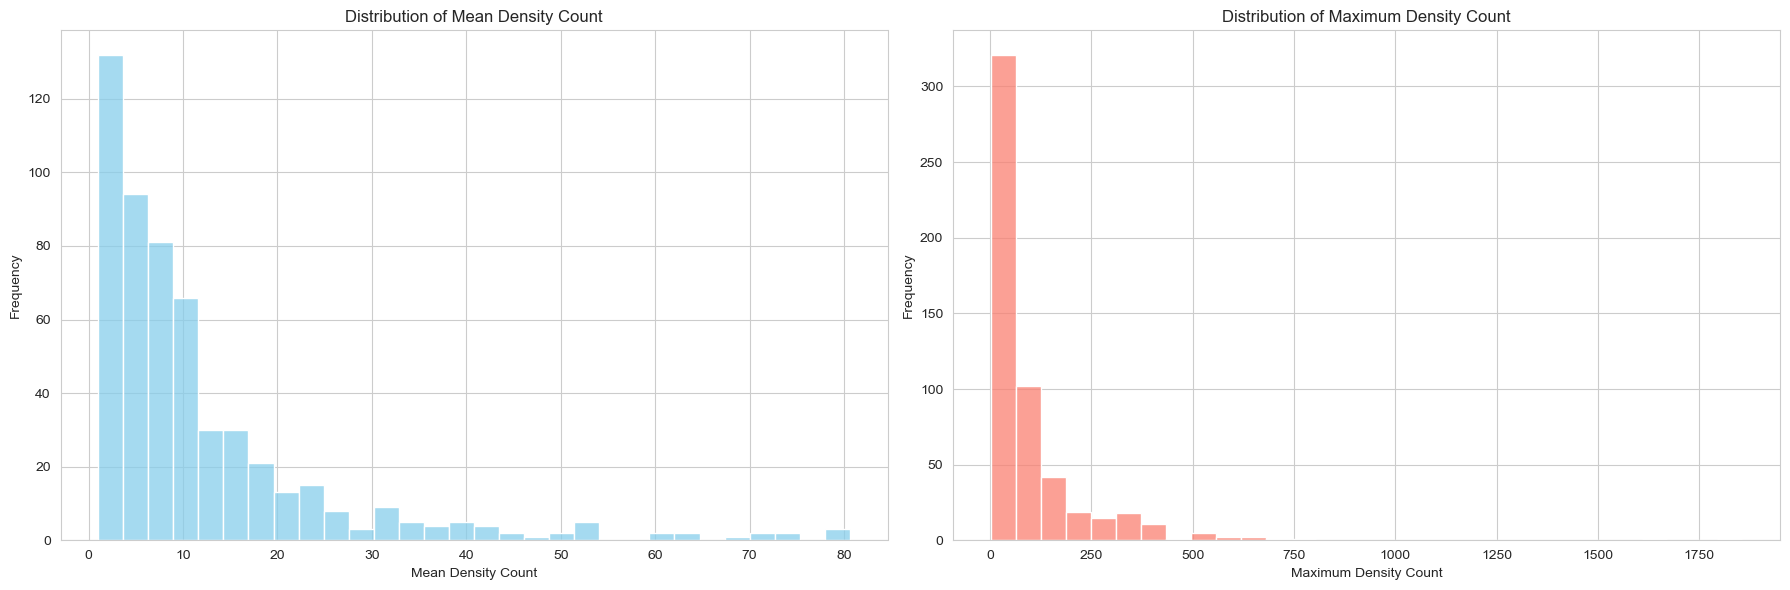

,building_desc,building_floor,building_type,mean_density_cnt,max_density_cnt
172,915 COMMONWEALTH AVENUE,1,Student Support,80.633535,353
106,33 HARRY AGGANIS WAY,1,Residential,79.651365,370
2,775 COMMONWEALTH AVENUE,1,Student Support,78.563533,534
115,890 COMMONWEALTH AVENUE,2,Academic,73.770378,367
8,2 SILBER WAY,1,Academic,73.431705,417


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the aesthetic style of the plots
sns.set_style("whitegrid")

# Plotting distributions of mean and maximum density counts
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Mean density count distribution
sns.histplot(data['mean_density_cnt'], bins=30, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Mean Density Count')
axes[0].set_xlabel('Mean Density Count')
axes[0].set_ylabel('Frequency')

# Maximum density count distribution
sns.histplot(data['max_density_cnt'], bins=30, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Maximum Density Count')
axes[1].set_xlabel('Maximum Density Count')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# Identify the top 5 locations with the highest mean density of users
top_mean_density_locations = data.sort_values(by='mean_density_cnt', ascending=False).head(5)
top_mean_density_locations[['building_desc', 'building_floor', 'building_type', 'mean_density_cnt', 'max_density_cnt']]

The distributions of mean and maximum density counts show a wide range of user densities across different locations, with a skew towards lower densities but with some locations experiencing significantly higher densities.

1. 915 Commonwealth Avenue (Student Support, Floor 1) with a mean density of approximately 80.63 users and a maximum density of 353 users.
2. 33 Harry Agganis Way (Residential, Floor 1) with a mean density of about 79.65 users and a maximum density of 370 users.
3. 775 Commonwealth Avenue (Student Support, Floor 1) with a mean density of roughly 78.56 users and a maximum density of 534 users.
4. 890 Commonwealth Avenue (Academic, Floor 2) with a mean density of around 73.77 users and a maximum density of 367 users.
5. 2 Silber Way (Academic, Floor 1) with a mean density of approximately 73.43 users and a maximum density of 417 users.

These findings suggest a significant concentration of Wi-Fi users in specific buildings, indicating high foot traffic or popular gathering spots. Academic and student support buildings appear to attract more users, likely due to classes, study areas, or administrative services housed there. The presence of a residential building among the top locations may indicate a high resident density or communal areas within residential buildings that encourage gathering.

In [6]:
import folium
from folium.plugins import MarkerCluster

# Initialize a map centered around the average latitude and longitude
avg_lat = data['latitude'].mean()
avg_lon = data['longitude'].mean()
wifi_map = folium.Map(location=[avg_lat, avg_lon], zoom_start=15)

# Create a marker cluster
marker_cluster = MarkerCluster().add_to(wifi_map)

# Add markers for the top 5 locations with the highest mean density
for idx, row in top_mean_density_locations.iterrows():
    location = (row['latitude'], row['longitude'])
    tooltip = f"{row['building_desc']} (Floor: {row['building_floor']})\nMean Density: {row['mean_density_cnt']}\nMax Density: {row['max_density_cnt']}"
    folium.Marker(location=location, 
                  popup=tooltip, 
                  icon=folium.Icon(color='red', icon='info-sign')).add_to(marker_cluster)

# Show the map
wifi_map.save('wifi_density_map.html')
'wifi_density_map.html'

'wifi_density_map.html'

I've created a map highlighting the top 5 locations with the highest mean density of Wi-Fi users. You can explore the geographical distribution and details of these hotspots by clicking on the markers.

---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

2. High Volume Event Spaces

In [7]:
# Let's start by loading the newly uploaded file to examine its structure and contents.
new_file_path = 'High Volume Event Spaces.xlsx - Sheet1.csv'
data_new = pd.read_csv(new_file_path)

# Display the first few rows to understand its structure
data_new.head()


,High Volume Event Spaces and Lounges,Unnamed: 1,Unnamed: 2,Unnamed: 3,BOTTLE FILLING,Unnamed: 5,Unnamed: 6
0,Room Name,Address,Floor,NaN,Current,NaN,Notes
1,Agganis Arena Burke Club Room,925 Commonwealth Avenue,2nd Floor,NaN,0,NaN,"casual catered events, high liklihood of using..."
2,Agganis Arena Friends of Hockey Lounge,925 Commonwealth Avenue,1st Floor,NaN,0,NaN,"casual catered events, high liklihood of using..."
3,Case Center Eilberg Lounge,285 Babcock Street,3rd Floor,NaN,??,NaN,use of the space is limited; there are fillers...
4,College of Arts & Sciences Classrooms,675-725 Commonwealth Avenue,NaN,NaN,NaN,complete FY23,There are a bunch already down the hallways; 4...


adjust the data import to treat the second row as the header and then perform a similar analysis to identify high-volume event spaces, focusing on any provided metrics and notes for insights.

In [8]:
# Adjusting the data import to correctly handle the header
data_new_corrected = pd.read_csv(new_file_path, header=1)

# Drop the unnecessary 'Unnamed' columns
data_new_corrected.drop(columns=[col for col in data_new_corrected.columns if "Unnamed" in col], inplace=True)

# Display the first few rows of the corrected dataframe
data_new_corrected.head()

,Room Name,Address,Floor,Current,Notes
0,Agganis Arena Burke Club Room,925 Commonwealth Avenue,2nd Floor,0,"casual catered events, high liklihood of using..."
1,Agganis Arena Friends of Hockey Lounge,925 Commonwealth Avenue,1st Floor,0,"casual catered events, high liklihood of using..."
2,Case Center Eilberg Lounge,285 Babcock Street,3rd Floor,??,use of the space is limited; there are fillers...
3,College of Arts & Sciences Classrooms,675-725 Commonwealth Avenue,NaN,NaN,There are a bunch already down the hallways; 4...
4,College of Communication Lounge,640 Commowealth Avenue,1st Floor,1,hallway by room 105


In [9]:
# Checking for unique values in the 'Current' column to understand its content better
unique_current_values = data_new_corrected['Current'].unique()

# Summarizing notes content by searching for keywords that might indicate high usage
keywords = ['high', 'limited', 'casual', 'events', 'hallway']
notes_summary = {keyword: data_new_corrected['Notes'].str.contains(keyword, case=False, na=False).sum() for keyword in keywords}

unique_current_values, notes_summary


(array(['0', '??', nan, '1'], dtype=object),
 {'high': 2, 'limited': 1, 'casual': 2, 'events': 8, 'hallway': 5})

- Events: Mentioned in 8 notes, suggesting these locations are indeed used for events, which can imply higher foot traffic.
- Hallway: Found in 5 notes, indicating these spaces might be near or in hallways, potentially suggesting areas of transit or gathering.
- High: Appears in 2 notes, possibly indicating high use or demand.
- Casual: Also in 2 notes, which might imply the space is used for casual gatherings.
- Limited: Mentioned in 1 note, which could indicate restricted use or access to the space.

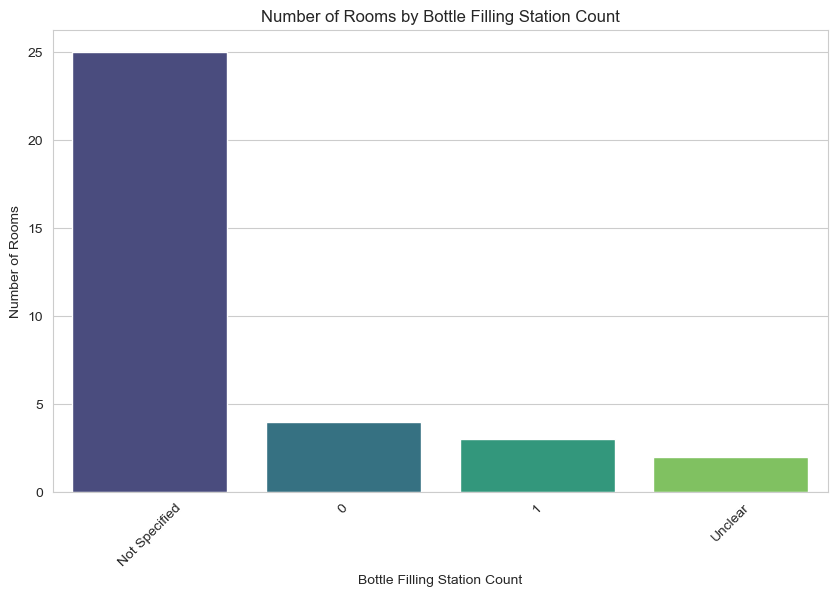

In [10]:
# Prepare data for visualization: Count the number of rooms with '0', '1', and unclear ('??') bottle filling station counts
bottle_filling_counts = data_new_corrected['Current'].replace('??', 'Unclear').fillna('Not Specified').value_counts()

# Visualization
plt.figure(figsize=(10, 6))
sns.barplot(x=bottle_filling_counts.index, y=bottle_filling_counts.values, palette='viridis')
plt.title('Number of Rooms by Bottle Filling Station Count')
plt.xlabel('Bottle Filling Station Count')
plt.ylabel('Number of Rooms')
plt.xticks(rotation=45)
plt.show()


The visualization shows the distribution of rooms categorized by the count of bottle filling stations, including those with clear counts ('0', '1'), those with an unclear status ('Unclear'), and where the status is not specified ('Not Specified'). This perspective provides an indirect indicator of which rooms might be equipped to handle high volumes of people, under the assumption that more equipped spaces (with bottle filling stations) anticipate or cater to higher traffic.

This analysis, combined with the insights from the notes, suggests that spaces marked for events, found in hallways, or explicitly mentioned as high traffic areas are likely the high-volume event spaces within the dataset. 

1. Identify Rooms Without Bottle Filling Stations: Focus on rooms marked with '0' or unclear ('??') in the Current column as primary candidates.
2. Prioritize Based on Keywords in Notes: Rooms with notes indicating high traffic, events, or strategic locations (e.g., hallways) might benefit the most from new installations.
3. Consider Event Spaces Specifically: Given that event spaces naturally attract higher volumes of people, they can be prioritized for impact.

In [11]:
# Filter rooms without bottle filling stations or with unclear status
candidates = data_new_corrected[data_new_corrected['Current'].isin(['0', '??'])]

# Add a 'Priority Score' based on the presence of keywords in notes
keywords_priority = ['events', 'hallway', 'high', 'casual', 'limited']
candidates['Priority Score'] = candidates['Notes'].apply(
    lambda x: sum(keyword in str(x).lower() for keyword in keywords_priority)
)

# Sort candidates by their priority score in descending order to see the top candidates for new bottle filling stations
top_candidates = candidates.sort_values(by='Priority Score', ascending=False)

top_candidates[['Room Name', 'Address', 'Floor', 'Current', 'Notes', 'Priority Score']]


C:\Users\Libra\AppData\Local\Temp\ipykernel_5052\3845474490.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  candidates['Priority Score'] = candidates['Notes'].apply(


,Room Name,Address,Floor,Current,Notes,Priority Score
0,Agganis Arena Burke Club Room,925 Commonwealth Avenue,2nd Floor,0,"casual catered events, high liklihood of using...",3
1,Agganis Arena Friends of Hockey Lounge,925 Commonwealth Avenue,1st Floor,0,"casual catered events, high liklihood of using...",3
2,Case Center Eilberg Lounge,285 Babcock Street,3rd Floor,??,use of the space is limited; there are fillers...,1
8,Dahod Family Alumni Center,225 Bay State Road,1st Floor,??,There's one in the space btw Castle and Admiss...,1
10,George Sherman Union Conference Rooms,775 Commonwealth Avenue,3rd Floor,0,used a lot for BU meetings... add to hallways ...,1
11,George Sherman Union Metcalf Hall,775 Commonwealth Avenue,2nd Floor,0,"There are 3 on the second floor, just not in t...",0


Based on the criteria for identifying spaces where new water bottle filling stations would be most impactful, the analysis highlights several top candidates prioritized by their potential need and benefit. Here are the rooms with the highest priority scores, indicating they lack clear bottle filling stations and are associated with high usage or strategic importance:

1. Agganis Arena Burke Club Room & Friends of Hockey Lounge (925 Commonwealth Avenue, 2nd Floor & 1st Floor, respectively): Both have a priority score of 3, with notes mentioning "casual catered events" and a "high likelihood of using disposable bottles."
2. Case Center Eilberg Lounge (285 Babcock Street, 3rd Floor): Has a priority score of 1, with notes suggesting limited use but potential need for fillers due to event usage.
3. Dahod Family Alumni Center (225 Bay State Road, 1st Floor) and George Sherman Union Conference Rooms (775 Commonwealth Avenue, 3rd Floor): Each has a priority score of 1. The Alumni Center's note mentions a nearby filling station, while the Conference Rooms are noted for frequent use for BU meetings, suggesting high traffic.
4. George Sherman Union Metcalf Hall (775 Commonwealth Avenue, 2nd Floor): Though it has a priority score of 0, it's highlighted due to its use and existing proximity to other filling stations, suggesting potential for increased coverage.

These locations, especially the top-ranked ones, represent strategic opportunities for the installation of new water bottle filling stations to support sustainability goals, enhance visitor experience, and reduce the usage of disposable bottles. Prioritizing spaces with high foot traffic, event usage, or those in strategic locations like hallways can maximize the impact of these installations.

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

3. Covered Floors

In [12]:
covered_data = pd.read_csv('covered_floors.csv')

covered_data.head()

,building_floor,building_desc,latitude,longitude,building_type,capacity,mean_density_cnt,max_density_cnt,average_dc_ratio,max_dc_ratio,Residential Building Type,Mechanical Ventilation
0,1,915 COMMONWEALTH AVENUE,42.3518,-71.1165,Student Support,204,80.633535,353,0.395262,1.730392,NaN,Yes
1,1,33 HARRY AGGANIS WAY,42.3532,-71.1178,Residential,84,79.651365,370,0.948231,4.404762,Large Dormitory-Style,Yes
2,1,775 COMMONWEALTH AVENUE,42.3509,-71.1090,Student Support,534,78.563533,534,0.147123,1.000000,NaN,Yes
3,2,890 COMMONWEALTH AVENUE,42.3505,-71.1156,Academic,238,73.770378,367,0.309960,1.542017,NaN,Yes
4,1,2 SILBER WAY,42.3497,-71.1009,Academic,87,73.431705,417,0.844043,4.793103,NaN,Yes


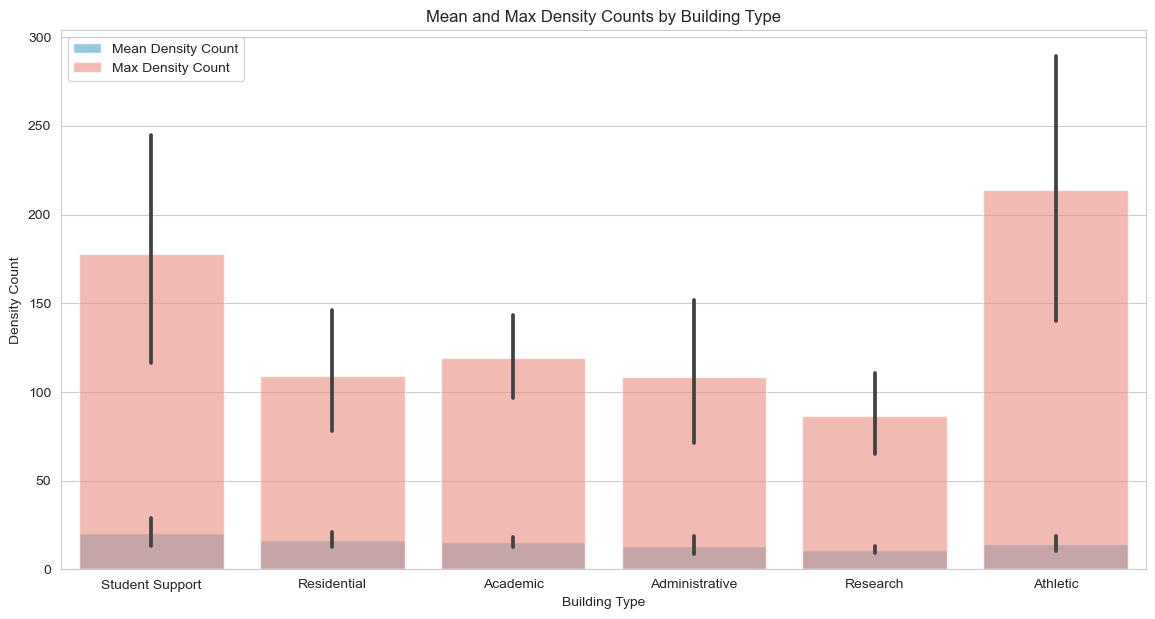

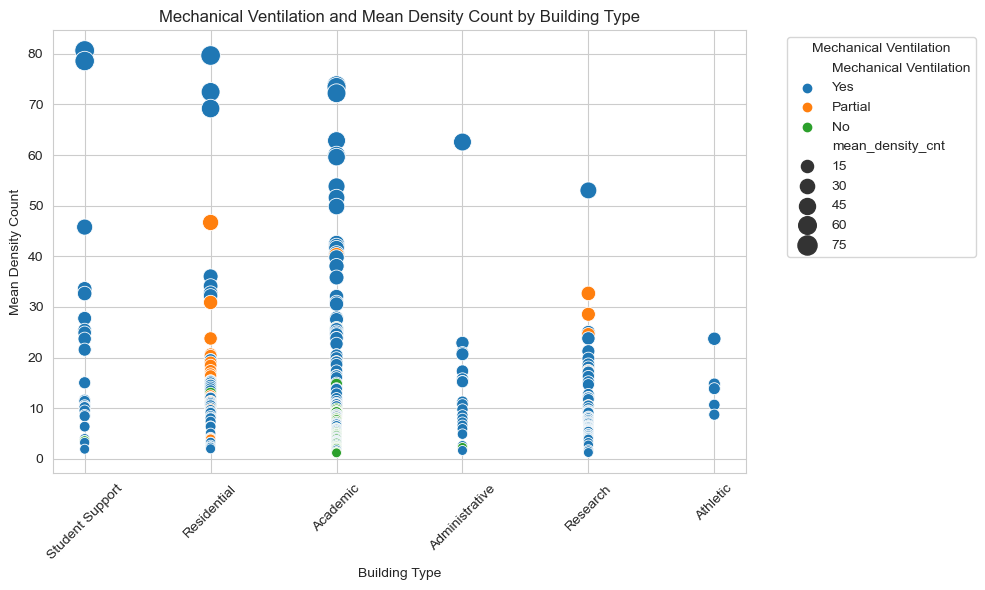

In [14]:
# Creating graphs for analysis:
# 1. Graph showing mean_density_cnt and max_density_cnt for each building type
# 2. Graph showing the presence of mechanical ventilation across buildings with high mean_density_cnt

# Graph 1: Mean and Max Density Counts by Building Type
plt.figure(figsize=(14, 7))
sns.barplot(x='building_type', y='mean_density_cnt', data=covered_data, color='skyblue', label='Mean Density Count')
sns.barplot(x='building_type', y='max_density_cnt', data=covered_data, color='salmon', label='Max Density Count', alpha=0.6)
plt.title('Mean and Max Density Counts by Building Type')
plt.xlabel('Building Type')
plt.ylabel('Density Count')
plt.legend()
plt.show()

# Graph 2: Presence of Mechanical Ventilation in High Density Areas
# Sorting data by mean density count to focus on higher density areas
covered_data_sorted = covered_data.sort_values(by='mean_density_cnt', ascending=False)
# Plotting
plt.figure(figsize=(10, 6))
sns.scatterplot(data=covered_data_sorted, x='building_type', y='mean_density_cnt', hue='Mechanical Ventilation', size='mean_density_cnt', sizes=(50, 200))
plt.title('Mechanical Ventilation and Mean Density Count by Building Type')
plt.xlabel('Building Type')
plt.ylabel('Mean Density Count')
plt.legend(title='Mechanical Ventilation', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

-------------------------------------------------------------------------------------------------------------------------------------------------------------------------

4. Selected Candidates 

In [15]:
# Load the data
data_path = 'selected_candidates.csv'
data = pd.read_csv(data_path)

# Preview the first few rows of the dataset
data.head()

,building_floor,building_desc,latitude,longitude,building_type,capacity,mean_density_cnt,max_density_cnt,average_dc_ratio,max_dc_ratio,Residential Building Type,Mechanical Ventilation,Room Name,Candidacy,High Volume,high_volumn
0,c,925 COMMONWEALTH AVENUE,42.3522,-71.1177,Athletic,0,48.954518,375,inf,inf,NaN,Yes,Agganis Arena Friends of Hockey Lounge,Maybe,Yes,True
1,1,949 COMMONWEALTH AVENUE,42.3519,-71.1187,Academic,45,45.248874,432,1.005531,9.600000,NaN,Yes,NaN,NaN,NaN,False
2,3,925 COMMONWEALTH AVENUE,42.3522,-71.1177,Athletic,29,41.111856,1857,1.417650,64.034483,NaN,Yes,NaN,NaN,NaN,False
3,2,8 ST. MARY'S STREET,42.3492,-71.1061,Research,145,39.097705,402,0.269639,2.772414,NaN,Yes,NaN,NaN,NaN,False
4,2,750 COMMONWEALTH AVENUE,42.3498,-71.1080,Academic,227,36.255775,318,0.159717,1.400881,NaN,Yes,NaN,NaN,NaN,False


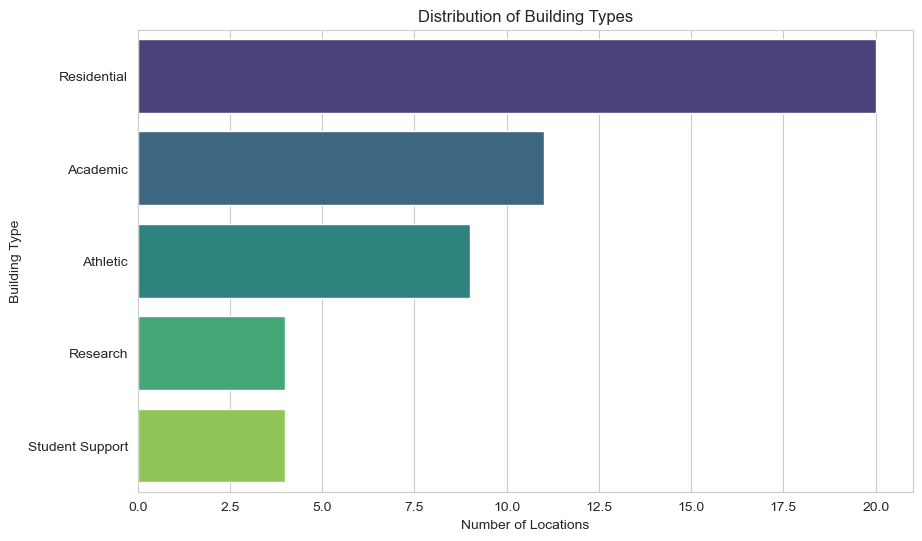

In [16]:
# Building Type Distribution
plt.figure(figsize=(10, 6))
building_type_counts = data['building_type'].value_counts()
sns.barplot(x=building_type_counts.values, y=building_type_counts.index, palette="viridis")
plt.title('Distribution of Building Types')
plt.xlabel('Number of Locations')
plt.ylabel('Building Type')
plt.show()

<Figure size 1200x800 with 0 Axes>

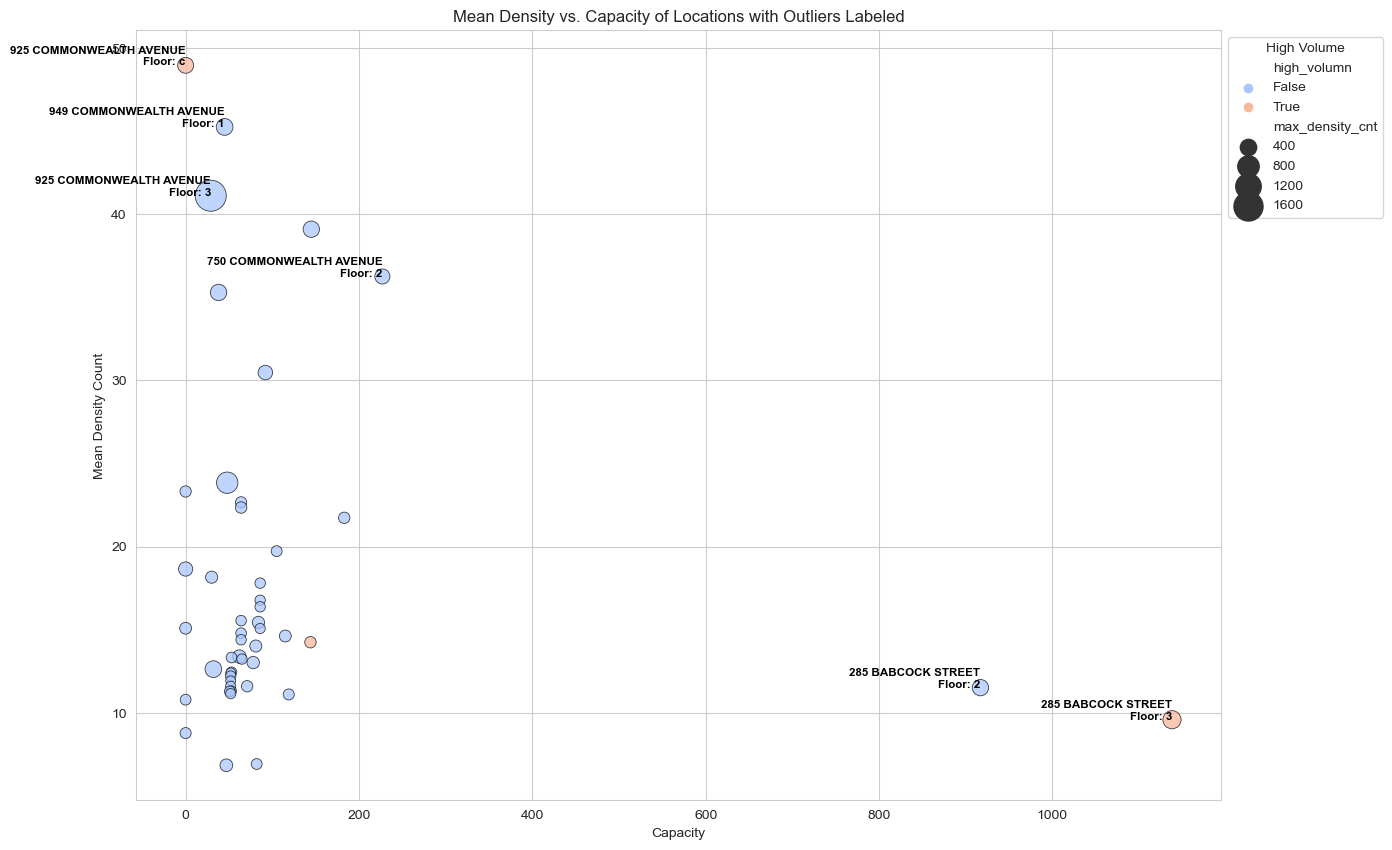

In [20]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

plt.figure(figsize=(12, 8))

# Identify outliers 
outliers = data[(data['mean_density_cnt'] > data['mean_density_cnt'].quantile(0.95)) | 
                (data['capacity'] > data['capacity'].quantile(0.95))]

plt.figure(figsize=(14, 10))

# plotting the scatter plot
scatter = sns.scatterplot(data=data, x='capacity', y='mean_density_cnt', hue='high_volumn', size='max_density_cnt',
                          sizes=(50, 500), palette='coolwarm', alpha=0.75, edgecolor="k")

# Adjust legend position
plt.legend(title='High Volume', loc='upper left', bbox_to_anchor=(1, 1))

plt.title('Mean Density vs. Capacity of Locations with Outliers Labeled')
plt.xlabel('Capacity')
plt.ylabel('Mean Density Count')
plt.grid(True)

# Loop through the outliers and annotate them
for _, outlier in outliers.iterrows():
    plt.text(outlier['capacity'], outlier['mean_density_cnt'], 
             f"{outlier['building_desc']}\nFloor: {outlier['building_floor']}", 
             horizontalalignment='right', size='small', color='black', weight='semibold')

plt.show()


The scatter plot above visualizes the relationship between the capacity of locations and their mean density count, with the size of each point indicating the maximum density count observed. The color coding distinguishes between high volume locations (true) and others (false).

Key observations from this plot include:

1. High Volume Locations: These are highlighted and tend to show higher mean density counts, indicating areas with significant foot traffic and potential high usage for water bottle filling stations.
2. Variation in Capacity and Density: There's a wide variation in both capacity and mean density across locations, suggesting a varied demand for water stations. Some locations with lower capacity still show high mean density, highlighting potential high-impact areas for new stations.
3. Max Density Count: The size of the points indicates the maximum density count, with some locations experiencing extremely high peak densities. These areas could be key targets for new installations to accommodate peak usage times.

This analysis suggests that both high volume locations and those with high mean density counts, regardless of their capacity, are prime candidates for new water bottle filling stations